# MathFeatures: combining variables with Feature-engine

MathFeatures applies pandas-style aggregation functions across selected numerical columns and adds the results to the dataframe. This notebook demonstrates sum, product, mean, minimum, maximum, and standard deviation with house-area variables.

## Why use MathFeatures?

Feature-engine keeps the formula as a reusable fit/transform object and preserves dataframe column names. This makes a domain feature easy to inspect and safe to insert into a scikit-learn pipeline.

In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('feature_engine') is None: subprocess.check_call([sys.executable,'-m','pip','install','feature-engine'])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from feature_engine.creation import MathFeatures

paths=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('../../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in paths if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
X=data[['GrLivArea','TotalBsmtSF','GarageArea','1stFlrSF','2ndFlrSF']].fillna(0)
display(X.head())

,GrLivArea,TotalBsmtSF,GarageArea,1stFlrSF,2ndFlrSF
0,1710,856,548,856,854
1,1262,1262,460,1262,0
2,1786,920,608,920,866
3,1717,756,642,961,756
4,2198,1145,836,1145,1053


## 1. Create named mathematical features

We combine four area measurements. The order of func and new_variables_names must match: sum creates total area, prod creates a multiplicative interaction, mean creates average area, and std captures spread among the components.

In [2]:
math_features=MathFeatures(
    variables=['GrLivArea','TotalBsmtSF','1stFlrSF','2ndFlrSF'],
    func=['sum','prod','mean','min','max','std'],
    new_variables_names=['total_selected_area','area_product','average_selected_area','minimum_selected_area','maximum_selected_area','area_spread'],
    missing_values='ignore',
)
X_created=math_features.fit_transform(X)
new_columns=[c for c in X_created.columns if c not in X.columns]
print('Created columns:',new_columns)
display(X_created[new_columns].head())

Created columns: ['total_selected_area', 'area_product', 'average_selected_area', 'minimum_selected_area', 'maximum_selected_area', 'area_spread']


,total_selected_area,area_product,average_selected_area,minimum_selected_area,maximum_selected_area,area_spread
0,4276.0,1.070044e+12,1069.00,854.0,1710.0,427.334373
1,3786.0,0.000000e+00,946.50,0.0,1262.0,631.000000
2,4492.0,1.309107e+12,1123.00,866.0,1786.0,442.732425
3,4190.0,9.430555e+11,1047.50,756.0,1717.0,456.675304
4,5541.0,3.034359e+12,1385.25,1053.0,2198.0,543.566233


## 2. Inspect distributions and feature names

Feature-engine returns a dataframe, so the newly generated columns can be plotted and passed to later transformations without losing their names.

,count,mean,std,min,25%,50%,75%,max
total_selected_area,1460.0,4.082510e+03,1.306310e+03,668.00,3168.00,3941.50,4.768500e+03,1.739400e+04
area_product,1460.0,1.003308e+12,5.087998e+12,0.00,0.00,0.00,8.468272e+11,1.536583e+14
average_selected_area,1460.0,1.020630e+03,3.265800e+02,167.00,792.00,985.38,1.192120e+03,4.348500e+03
minimum_selected_area,1460.0,3.220600e+02,4.079400e+02,0.00,0.00,0.00,7.020000e+02,2.065000e+03
maximum_selected_area,1460.0,1.517950e+03,5.309800e+02,334.00,1130.75,1466.00,1.779000e+03,6.110000e+03
area_spread,1460.0,5.742100e+02,1.939300e+02,192.83,432.00,536.34,6.826900e+02,2.341210e+03


Transformer feature names: ['GrLivArea', 'TotalBsmtSF', 'GarageArea', '1stFlrSF', '2ndFlrSF', 'total_selected_area', 'area_product', 'average_selected_area', 'minimum_selected_area', 'maximum_selected_area', 'area_spread']


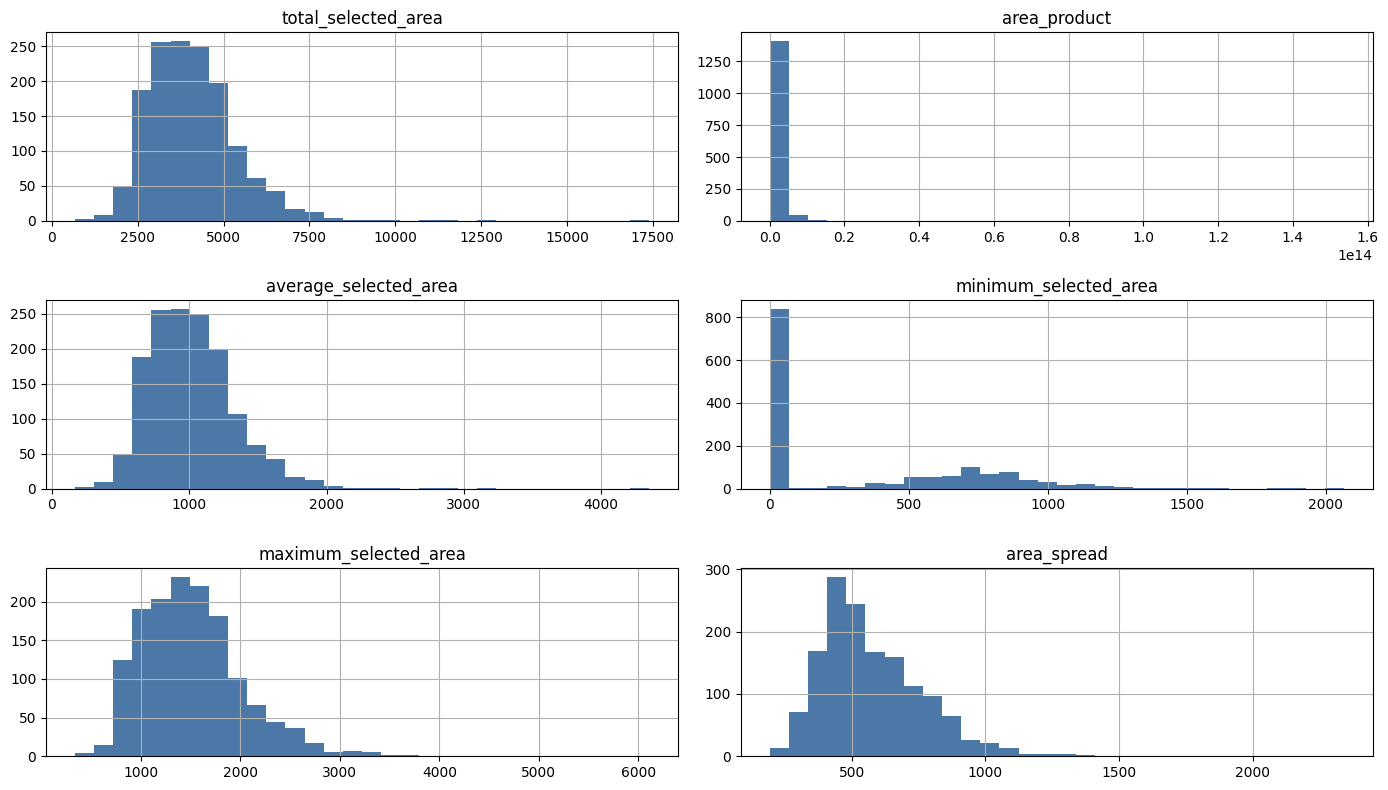

In [3]:
display(X_created[new_columns].describe().T.round(2))
print('Transformer feature names:',math_features.get_feature_names_out())
X_created[new_columns].hist(bins=30,figsize=(14,8),color='#4C78A8'); plt.tight_layout(); plt.show()

## Practical checks

Use MathFeatures for formulas with a clear domain meaning. Products can become very large, standard deviations can be undefined for a single value, and missing-value behaviour must be selected deliberately. Fit it on the training dataframe and transform the test dataframe with the same transformer.

In [4]:
assert np.isfinite(X_created[new_columns].to_numpy()).all()
assert X_created.shape[0]==X.shape[0]
print('Rows preserved:',X_created.shape[0])
print('Columns before/after:',X.shape[1],X_created.shape[1])

Rows preserved: 1460
Columns before/after: 5 11


## Summary

MathFeatures packages mathematical combinations into an sklearn-compatible transformer. Named features make the calculation understandable and help prevent the training and inference code from drifting apart.